# Cooperative Sheaf Neural Networks

In every sheaf model so far, an edge is a two-way street with one map per endpoint, so a node that sends information along an edge also receives along it. **Cooperative Sheaf Neural Networks** (CSNN; Ribeiro et al., 2025) separate the two roles. Every node learns an **outgoing** restriction map (how it *broadcasts*) and an **incoming** map (how it *listens*), and both are **conformal**: a rotation times a positive scale. A node can therefore decide to speak loudly but listen little, or the opposite, and the paper shows that this cooperative behaviour helps against oversquashing.

### What You Will Learn
* Why splitting an edge into two directed halves gives each node two independent restriction maps.
* What conformal maps $c\,Q$ are, and what their scale $c$ means for the flow of information.
* How the repository's `CSNNConv` composes an outgoing and an incoming sheaf Laplacian.
* How to read a trained CSNN: which nodes chose to broadcast and which chose to listen, and whether that matches what the task rewards.

### Notebook Roadmap
1. **Motivate** cooperative message passing.
2. **Formalize** directed restriction maps, conformal scales, and the CSNN layer.
3. **Build** a toy graph with reliable and unreliable nodes.
4. **Train** conformal and non-conformal CSNNs next to NSD and an MLP.
5. **Interpret** the learned broadcast and listening strengths.

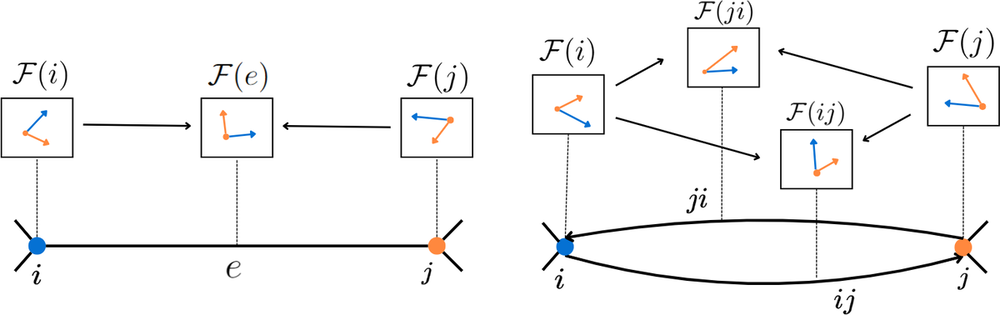

*Left: a cellular sheaf on a single undirected edge, with stalks isomorphic to R^2 and one restriction map per endpoint. Right: the analogous sheaf on a pair of directed edges ij and ji, which carries four, possibly distinct, restriction maps, so that sending and receiving can be controlled separately.*

<sub>Source: Ribeiro et al. (2025), *Cooperative Sheaf Neural Networks*, [arXiv:2507.00647](https://arxiv.org/abs/2507.00647), Fig. 1. Reproduced for teaching with attribution (arXiv non-exclusive distribution licence).</sub>

## Table of Contents

1. [Introduction](#1-introduction)
2. [Environment Setup and Imports](#2-env-setup)
3. [Cooperative Sheaves](#3-cooperative-sheaves)
    * [Two Maps per Node](#two-maps)
    * [Conformal Maps](#conformal-maps)
    * [The CSNN Layer in the Repository](#csnn-layer)
4. [Dataset Pipeline: Reliable and Unreliable Nodes](#4-dataset-pipeline)
5. [Model Construction](#5-model-construction)
6. [Training Pipeline](#6-training-pipeline)
7. [Interpreting Cooperative Behaviour](#7-interpretation)
    * [Who Broadcasts, Who Listens?](#broadcast-listen)
    * [Scales Across Layers](#scales-across-layers)
8. [Configuration, Reproducibility, and Exercises](#8-exercises)

<a id="1-introduction"></a>
# 1. Introduction

Message passing is **democratic**: every node sends its state to all neighbours and accepts theirs, with weights fixed by the topology (GCN) or by a symmetric comparison (attention, sheaves). Real systems are rarely like that. A reliable sensor should be heard but has little to learn from noisy neighbours, while an unreliable one should mostly *listen*. Hubs may want to stop listening to avoid being flooded, and peripheral nodes may want to stop broadcasting irrelevant information.

CSNN turns these choices into learnable geometry. Every node $v$ predicts:
* an **outgoing** map $\mathbf{T}_v = c^{\text{out}}_v\, Q^{\text{out}}_v$ that shapes what it sends;
* an **incoming** map $\mathbf{S}_v = c^{\text{in}}_v\, Q^{\text{in}}_v$ that shapes what it receives.

A small $c^{\text{out}}_v$ means "I barely broadcast", and a small $c^{\text{in}}_v$ means "I barely listen". The orthogonal parts $Q$ still rotate the features into each other's frames, as in orthogonal NSD.

<a id="2-env-setup"></a>
# 2. Environment Setup and Imports

Use the repository's Python 3.13 environment (`uv sync`) and run the notebook top to bottom from a fresh kernel. Everything runs on CPU in about a minute.

In [1]:
# =====================================================================
# 1. Standard Library & Repository Path
# =====================================================================
import copy
import random
import sys
import warnings
from pathlib import Path


def find_repo_root(start: Path | None = None) -> Path:
    """Find the repository root (the folder holding pyproject.toml and src/)."""
    start = (start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "src").exists():
            return p
    raise FileNotFoundError("Could not locate the repository")


REPO_ROOT = find_repo_root()
SRC_PATH = REPO_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

# =====================================================================
# 2. Core Scientific Libraries
# =====================================================================
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data

# =====================================================================
# 3. Reproducibility
# =====================================================================
warnings.filterwarnings("ignore")
SEED = 42


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)  # noqa: NPY002
    torch.manual_seed(seed)


set_seed(SEED)
torch.set_num_threads(1)  # small graphs: avoid thread overhead and nondeterminism

print("--- Environment Status ---")
print(f"Repository root: {REPO_ROOT}")
print(f"Python:  {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")

# =====================================================================
# 4. Repository-Specific Modules
# =====================================================================
from torch_geometric.utils import homophily, stochastic_blockmodel_graph

from sheaf_mpnn.csnn import CSNNModel, CSNNVariant
from sheaf_mpnn.nsd import NSDModel, NSDVariant

print("Loaded CSNNModel and the NSD baseline.")

--- Environment Status ---
Repository root: <repo>
Python:  3.13.12
PyTorch: 2.8.0
Loaded CSNNModel and the NSD baseline.


<a id="3-cooperative-sheaves"></a>
# 3. Cooperative Sheaves

<a id="two-maps"></a>
### 3.1 Two Maps per Node

Replace every undirected edge $\{i, j\}$ by the two directed edges $ij$ and $ji$, each with its own edge stalk. A sheaf on this directed graph has **four** restriction maps per original edge: the sender's and receiver's maps on $ij$, and those on $ji$ (figure above). CSNN ties these maps to the nodes: on every edge $u \to v$, the sender uses its outgoing map $\mathbf{T}_u$ and the receiver its incoming map $\mathbf{S}_v$. Each node therefore learns two maps in total, and the transport from $u$ to $v$, $\mathbf{S}_v^{\top}\mathbf{T}_u$, is different from the transport from $v$ to $u$, $\mathbf{S}_u^{\top}\mathbf{T}_v$.

The paper shows that this asymmetry lets the model **route** information. On a path graph, appropriate maps can open a one-way channel from one end to the other, with nothing flowing back:

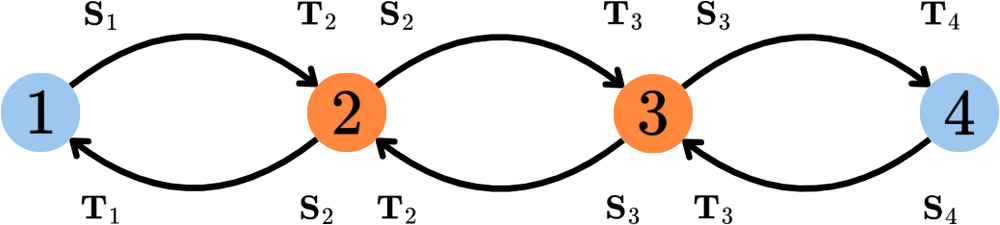

*The path-graph example of the paper. At layer t, all maps except T_{4-t,t} and S_{4-(t-1),t} are zero, which lets information flow from right to left along the bottom edges, a directed channel that symmetric message passing cannot express.*

<sub>Source: Ribeiro et al. (2025), *Cooperative Sheaf Neural Networks*, [arXiv:2507.00647](https://arxiv.org/abs/2507.00647), Fig. 4. Reproduced for teaching with attribution (arXiv non-exclusive distribution licence).</sub>

<a id="conformal-maps"></a>
### 3.2 Conformal Maps

A linear map is **conformal** if it preserves angles. In matrix form, it is $c\,Q$ with $Q$ orthogonal and $c > 0$. Compared with a general matrix, a conformal map cannot shear or squash one direction more than another. Compared with an orthogonal map, it can change the **strength** of the signal it carries. That single scalar $c$ is what lets a node turn its volume up or down without distorting the geometry of the features. The `NON_CONFORMAL` variant fixes $c = 1$ (pure orthogonal maps) and serves as the ablation.

The cell below checks both properties numerically for a random rotation and three scales.

c = 0.5: angle(u, v) = 53.1 deg -> angle(cQu, cQv) = 53.1 deg; |cQu| = 0.50
c = 1.0: angle(u, v) = 53.1 deg -> angle(cQu, cQv) = 53.1 deg; |cQu| = 1.00
c = 2.0: angle(u, v) = 53.1 deg -> angle(cQu, cQv) = 53.1 deg; |cQu| = 2.00


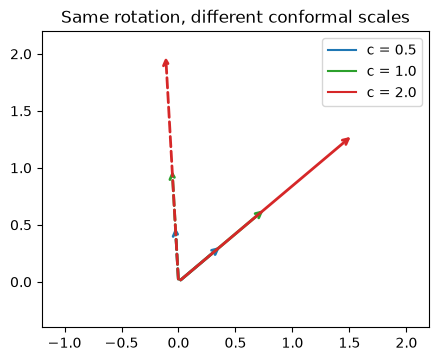

In [2]:
# =====================================================================
# Conformal maps preserve angles and scale every length by c
# =====================================================================
theta = torch.tensor(0.7)
Q = torch.stack(
    [torch.stack([theta.cos(), -theta.sin()]), torch.stack([theta.sin(), theta.cos()])]
)
u, v = torch.tensor([1.0, 0.0]), torch.tensor([0.6, 0.8])


def angle(a, b):
    return torch.rad2deg(torch.arccos((a @ b) / (a.norm() * b.norm()))).item()


fig, ax = plt.subplots(figsize=(5, 5))
for scale, colour in [(0.5, "tab:blue"), (1.0, "tab:green"), (2.0, "tab:red")]:
    for vec, ls in [(u, "-"), (v, "--")]:
        w = scale * Q @ vec
        ax.annotate(
            "",
            xy=w.numpy(),
            xytext=(0, 0),
            arrowprops=dict(arrowstyle="->", color=colour, ls=ls, lw=2),
        )
    ax.plot([], [], color=colour, label=f"c = {scale}")
    print(
        f"c = {scale}: angle(u, v) = {angle(u, v):.1f} deg -> angle(cQu, cQv) = {angle(scale * Q @ u, scale * Q @ v):.1f} deg; "
        f"|cQu| = {(scale * Q @ u).norm():.2f}"
    )
ax.set(
    xlim=(-1.2, 2.2),
    ylim=(-0.4, 2.2),
    title="Same rotation, different conformal scales",
)
ax.set_aspect("equal")
ax.legend()
plt.show()
assert torch.allclose(Q.T @ Q, torch.eye(2), atol=1e-6)

<a id="csnn-layer"></a>
### 3.3 The CSNN Layer in the Repository

`CSNNConv` (`src/sheaf_mpnn/csnn/csnn_layers.py`) works with per-node maps predicted by two independent learners, `out_maps_learner` and `in_maps_learner`. Each learner is a small MLP or GNN that outputs orthogonal-map parameters plus, in the conformal variant, one extra channel decoded as $c = \exp(\cdot)$, capped at 10. One layer then:
1. transforms the stalks with left ($d \times d$) and right ($f \times f$) weights, like $W_1$ and $W_2$ in NSD;
2. applies an **outgoing** sheaf Laplacian built from the $\mathbf{T}$ maps, then an **incoming** one built from the $\mathbf{S}$ maps. Both are normalized by $(D + 1)^{-1/2}$, where the degrees are sums of squared conformal scales;
3. adds a gated skip: $\mathbf{x}^{+} = (1 + \tanh\boldsymbol{\varepsilon}) \odot \mathbf{x} - \mathcal{L}_{\text{in}}\mathcal{L}_{\text{out}}(\cdots)$.

The scales enter both the transports and the degrees. The *relative* size of a node's $c^{\text{out}}$ and $c^{\text{in}}$ against its neighbours' therefore decides how much it contributes and absorbs.

<a id="4-dataset-pipeline"></a>
# 4. Dataset Pipeline: Reliable and Unreliable Nodes

To give cooperation something to do, we build a **homophilic** two-class graph (edge homophily around 0.85) in which nodes differ in how trustworthy their features are:
* **reliable** nodes see their own label clearly: a strong class offset in the first feature;
* **unreliable** nodes see only noise;
* a binary *reliability flag* is part of the features, so the map learners *can* tell the two kinds apart. Whether they use the flag is up to training.

Because neighbours usually share the label, an unreliable node is best served by **listening** to its neighbours, and a reliable node by **broadcasting** its own evidence. A plain average treats everyone alike and lets the noisy half dilute the signal.

In [3]:
def random_splits(n: int, train: float = 0.4, val: float = 0.2, seed: int = SEED):
    """Disjoint boolean train/val/test masks over n nodes."""
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=g)
    n_train, n_val = int(train * n), int(val * n)
    masks = [torch.zeros(n, dtype=torch.bool) for _ in range(3)]
    masks[0][perm[:n_train]] = True
    masks[1][perm[n_train : n_train + n_val]] = True
    masks[2][perm[n_train + n_val :]] = True
    return masks


# =====================================================================
# Homophilic graph with reliable and unreliable nodes
# =====================================================================
set_seed(SEED)
n, h, avg_degree = 160, 0.85, 6
half = n // 2
p_in, p_out = h * avg_degree / half, (1 - h) * avg_degree / half
edge_index = stochastic_blockmodel_graph([half, half], [[p_in, p_out], [p_out, p_in]])
y = torch.cat([torch.zeros(half), torch.ones(half)]).long()

reliable = torch.rand(n) < 0.5
x = torch.randn(n, 4)
x[reliable, 0] += 1.5 * (
    2 * y[reliable].float() - 1
)  # only reliable nodes carry the label signal
x = torch.cat(
    [x, reliable.float()[:, None]], dim=1
)  # the reliability flag as a fifth feature

train_mask, val_mask, test_mask = random_splits(n)
data = Data(
    x=x,
    y=y,
    edge_index=edge_index,
    train_mask=train_mask,
    val_mask=val_mask,
    test_mask=test_mask,
)

print("--- Toy graph ---")
print(data)
print(f"Edge homophily: {homophily(edge_index, y, method='edge'):.3f}")
print(f"Reliable nodes: {int(reliable.sum())} / {n}")

--- Toy graph ---
Data(x=[160, 5], edge_index=[2, 972], y=[160], train_mask=[160], val_mask=[160], test_mask=[160])
Edge homophily: 0.874
Reliable nodes: 82 / 160


<a id="5-model-construction"></a>
# 5. Model Construction

We compare four models with the same width ($d = 2$, 8 channels per stalk, two layers):
* **CSNN, conformal**: learned broadcast and listening strengths;
* **CSNN, non-conformal**: the same model with all scales fixed to 1;
* **NSD** with diagonal maps: symmetric, per-edge maps;
* an **MLP** on the features alone.

The CSNN map learners are two-layer MLPs here (`gnn_layers=0`); the repository also supports GNN learners.

In [4]:
# =====================================================================
# Model factories
# =====================================================================
def csnn_model(variant):
    return CSNNModel(
        5,
        2,
        stalk_dim=2,
        hidden_dim=8,
        num_layers=2,
        variant=variant,
        gnn_layers=0,
        gnn_hidden=16,
        orth_strategy="cayley",
    )


def nsd_model():
    return NSDModel(
        5, 2, stalk_dim=2, hidden_dim=8, num_layers=2, variant=NSDVariant.DIAGONAL
    )


def mlp_model():
    return nn.Sequential(nn.Linear(5, 16), nn.ELU(), nn.Linear(16, 2))


demo = csnn_model(CSNNVariant.CONFORMAL)
layer0 = demo.layers[0]
print(f"Layer: {type(layer0).__name__}")
print(
    f"out_maps_learner: {type(layer0.out_maps_learner).__name__} (conformal={layer0.out_maps_learner.conformal})"
)
print(
    f"in_maps_learner:  {type(layer0.in_maps_learner).__name__} (conformal={layer0.in_maps_learner.conformal})"
)
print(f"Parameters: {sum(p.numel() for p in demo.parameters()):,}")

Layer: CSNNConv
out_maps_learner: ConformalSheafLearner (conformal=True)
in_maps_learner:  ConformalSheafLearner (conformal=True)
Parameters: 1,494


<a id="6-training-pipeline"></a>
# 6. Training Pipeline

Each model is trained with three seeds using masked cross-entropy and validation-based selection.

In [5]:
# =====================================================================
# Masked training with validation-based model selection
# =====================================================================
def accuracy(logits: torch.Tensor, y: torch.Tensor, mask: torch.Tensor) -> float:
    return (logits[mask].argmax(-1) == y[mask]).float().mean().item()


def train_model(
    model, predict, data, epochs=150, lr=0.01, weight_decay=5e-4, extra_loss=None
):
    """Adam on masked cross-entropy; restores the state with the lowest validation loss.

    Args:
        model: the network to optimize.
        predict: zero-argument callable returning logits [N, C] for the whole graph.
        data: PyG Data with y, train_mask, val_mask, test_mask.
        epochs: number of full-batch optimization steps.
        lr: Adam learning rate.
        weight_decay: Adam L2 penalty.
        extra_loss: optional callable(epoch) -> scalar added to the loss (e.g. a KL term).

    Returns:
        (history, test_accuracy) where history holds one dict per epoch.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history, best_val, best_state = [], float("inf"), None
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        logits = predict()
        loss = F.cross_entropy(logits[data.train_mask], data.y[data.train_mask])
        if extra_loss is not None:
            loss = loss + extra_loss(epoch)
        assert torch.isfinite(loss), "non-finite training loss"
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_logits = predict()
            val_loss = F.cross_entropy(
                val_logits[data.val_mask], data.y[data.val_mask]
            ).item()
        history.append(
            {
                "train_loss": loss.item(),
                "val_loss": val_loss,
                "val_acc": accuracy(val_logits, data.y, data.val_mask),
            }
        )
        if val_loss < best_val:
            best_val, best_state = val_loss, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        test_acc = accuracy(predict(), data.y, data.test_mask)
    return history, test_acc


def plot_history(history, title):
    """Training/validation curves of one run."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    axes[0].plot([h["train_loss"] for h in history], label="train loss")
    axes[0].plot([h["val_loss"] for h in history], label="validation loss")
    axes[0].set(xlabel="epoch", ylabel="cross-entropy", title=title)
    axes[0].legend()
    axes[1].plot([h["val_acc"] for h in history], color="tab:green")
    axes[1].set(
        xlabel="epoch",
        ylabel="validation accuracy",
        ylim=(0, 1.02),
        title="Validation accuracy",
    )
    plt.tight_layout()
    plt.show()


# =====================================================================
# Train the four models
# =====================================================================
setups = {
    "CSNN conformal": lambda: csnn_model(CSNNVariant.CONFORMAL),
    "CSNN non-conformal": lambda: csnn_model(CSNNVariant.NON_CONFORMAL),
    "NSD (diagonal)": nsd_model,
    "MLP (features only)": mlp_model,
}
results, trained = {}, {}
for name, factory in setups.items():
    accs = []
    for seed in (0, 1, 2):
        set_seed(seed)
        model = factory()
        if name.startswith("MLP"):

            def predict(m=model):
                return m(data.x)
        else:

            def predict(m=model):
                return m(data.x, data.edge_index)

        history, acc = train_model(model, predict, data, epochs=200)
        accs.append(acc)
        if seed == 0:
            trained[name] = (model, history)
    results[name] = accs

print("--- Test accuracy (3 seeds) ---")
for name, accs in results.items():
    print(f"{name:<20} {np.mean(accs):.3f} +/- {np.std(accs):.3f}")
reliable_test = test_mask & reliable
unreliable_test = test_mask & ~reliable
print("\n--- Seed-0 accuracy by node kind ---")
for name, (model, _) in trained.items():
    model.eval()
    with torch.no_grad():
        logits = (
            model(data.x) if name.startswith("MLP") else model(data.x, data.edge_index)
        )
    print(
        f"{name:<20} reliable {accuracy(logits, y, reliable_test):.3f} | unreliable {accuracy(logits, y, unreliable_test):.3f}"
    )

--- Test accuracy (3 seeds) ---
CSNN conformal       0.818 +/- 0.064
CSNN non-conformal   0.901 +/- 0.060
NSD (diagonal)       0.953 +/- 0.013
MLP (features only)  0.719 +/- 0.022

--- Seed-0 accuracy by node kind ---
CSNN conformal       reliable 0.872 | unreliable 0.760
CSNN non-conformal   reliable 0.897 | unreliable 0.840
NSD (diagonal)       reliable 0.974 | unreliable 0.920
MLP (features only)  reliable 0.923 | unreliable 0.480


**Reading the table.** The MLP can only classify reliable nodes, since the unreliable ones carry no signal, so its accuracy on unreliable nodes sits near chance. Every graph model lifts the unreliable nodes far above chance by importing their neighbours' evidence: the split by node kind shows *where* each model's accuracy comes from.

Among the graph models, more freedom is not automatically better. On this small, strongly homophilic graph, plain NSD is typically the most accurate, and the conformal CSNN often the least. Its extra scales add parameters that 64 labels cannot fully constrain, and its seed-to-seed spread is larger. That is a statement about this toy, not about CSNN in general. The question for the next section is different: *did* the conformal model learn the cooperative roles the task rewards?

<a id="7-interpretation"></a>
# 7. Interpreting Cooperative Behaviour

<a id="broadcast-listen"></a>
### 7.1 Who Broadcasts, Who Listens?

For the trained conformal CSNN, we recompute the first layer's scales with its own learners, applied to exactly the input that `CSNNModel.forward` gives them (the GELU-activated encoder output). Every node gets a point $(c^{\text{out}}_v, c^{\text{in}}_v)$. If the model has learned the cooperative strategy the task rewards, reliable nodes should sit towards *high broadcast* and unreliable nodes towards *high listening*.

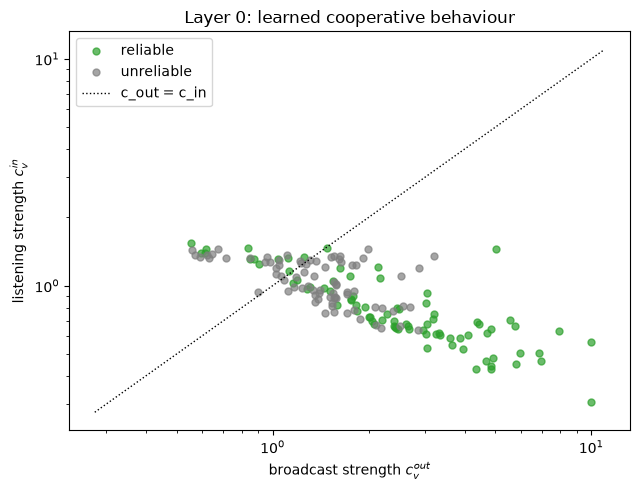

reliable    median c_out 2.444 | median c_in 0.711 | median c_out / c_in 3.455
unreliable  median c_out 1.460 | median c_in 1.075 | median c_out / c_in 1.386


In [6]:
# =====================================================================
# Conformal scales of the first layer, per node
# =====================================================================
csnn = trained["CSNN conformal"][0].eval()


def layer_scales(model, layer_index):
    """(c_out, c_in) of one layer, recomputed from its input as in CSNNModel.forward."""
    inputs = []
    hook = model.layers[layer_index].register_forward_pre_hook(
        lambda mod, args: inputs.append(args[0])
    )
    with torch.no_grad():
        model(data.x, data.edge_index)
    hook.remove()
    layer = model.layers[layer_index]
    with torch.no_grad():
        _, c_out = layer.out_maps_learner(inputs[0], data.edge_index)
        _, c_in = layer.in_maps_learner(inputs[0], data.edge_index)
    return c_out.numpy(), c_in.numpy()


c_out, c_in = layer_scales(csnn, 0)
fig, ax = plt.subplots(figsize=(6.5, 5))
for mask, colour, label in [
    (reliable, "tab:green", "reliable"),
    (~reliable, "tab:gray", "unreliable"),
]:
    ax.scatter(c_out[mask], c_in[mask], s=25, alpha=0.7, color=colour, label=label)
lims = [min(c_out.min(), c_in.min()) * 0.9, max(c_out.max(), c_in.max()) * 1.1]
ax.plot(lims, lims, "k:", lw=1, label="c_out = c_in")
ax.set(
    xscale="log",
    yscale="log",
    xlabel=r"broadcast strength $c^{out}_v$",
    ylabel=r"listening strength $c^{in}_v$",
    title="Layer 0: learned cooperative behaviour",
)
ax.legend()
plt.tight_layout()
plt.show()

for name, mask in [("reliable", reliable), ("unreliable", ~reliable)]:
    print(
        f"{name:<11} median c_out {np.median(c_out[mask]):.3f} | median c_in {np.median(c_in[mask]):.3f} | "
        f"median c_out / c_in {np.median(c_out[mask] / c_in[mask]):.3f}"
    )

Read the plot through the ratio $c^{\text{out}}/c^{\text{in}}$. Points below the diagonal broadcast more than they listen, and points above it listen more than they broadcast. A clear separation between the two colours means the learners use the reliability information to assign *roles*. A complete overlap means the model treats all nodes alike, so its accuracy must come from the transports and the update weights. Keep in mind that only the *relative* scales matter: the degree normalization divides by sums of squared scales, so multiplying every $c$ by the same constant changes nothing.

<a id="scales-across-layers"></a>
### 7.2 Scales Across Layers

Each layer has its own learners, so the roles can change with depth. A common pattern is to gather evidence in the first layer and spread the resulting consensus in the next. We compare the ratio $c^{\text{out}}/c^{\text{in}}$ of both layers for the two kinds of nodes.

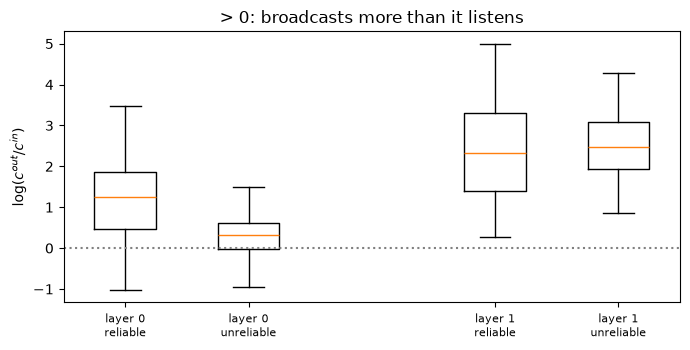

In [7]:
# =====================================================================
# Broadcast/listen ratio per layer and node kind
# =====================================================================
fig, ax = plt.subplots(figsize=(7, 3.6))
positions, labels, values = [], [], []
for i in range(len(csnn.layers)):
    co, ci = layer_scales(csnn, i)
    ratio = np.log(co / ci)
    for j, (name, mask) in enumerate(
        [("reliable", reliable.numpy()), ("unreliable", ~reliable.numpy())]
    ):
        values.append(ratio[mask])
        positions.append(3 * i + j)
        labels.append(f"layer {i}\n{name}")
ax.boxplot(values, positions=positions)
ax.set_xticks(positions, labels, fontsize=8)
ax.axhline(0, color="gray", ls=":")
ax.set(ylabel=r"$\log(c^{out}/c^{in})$", title="> 0: broadcasts more than it listens")
plt.tight_layout()
plt.show()

<a id="8-exercises"></a>
# 8. Configuration, Reproducibility, and Exercises

**Using it on real data.** CSNN is the `CSNN` model type (and `HET_CSNN` for heterogeneous graphs). The map learner is configured with the `gnn-*` flags:

```bash
sheaf run --preset texas_csnn
sheaf run --preset chameleon_csnn --model.variant non_conformal          # ablate the scales
sheaf run --preset texas_csnn --model.gnn-layers 2 --model.gnn-default 1  # GNN map learners
```

Record the variant, the learner backbone (`gnn_layers`, `gnn_default`, `gnn_type`), the orthogonal parameterization, and the seed. The package README in `src/sheaf_mpnn/csnn/` documents the remaining options.

**Key takeaways**
* Splitting each edge into two directed halves gives every node an outgoing and an incoming map, so sending and receiving are controlled separately.
* Conformal maps $c\,Q$ add a volume knob to orthogonal transport without distorting angles.
* A trained CSNN is readable: its per-node scales show which nodes it treats as sources and which as sinks of information.

### Hands-on Exercises
1. **Hide the flag.** Remove the reliability flag from the features. Can the learners still discover which nodes are reliable, for example from $|x_0|$?
2. **GNN learners.** Set `gnn_layers=1`. The learners then see the neighbourhood when predicting the maps. Does the separation of roles become clearer?
3. **Heterophily.** Rebuild the graph with $h = 0.15$. What roles do the reliable nodes take now, and how do the orthogonal parts $Q$ change?
4. **Routing.** On a path graph, construct (by hand, without training) outgoing and incoming maps that send information only from right to left, as in the paper's figure. Verify it with a few propagation steps.